# Modul 8 — Regresi: Linear Regression, Ridge, dan Lasso

**Regresi** memprediksi **angka** (misalnya besar tip, harga rumah), berbeda dengan klasifikasi di Modul 6–7 yang memprediksi **kategori**.

- **Linear Regression (OLS):** mencari satu garis lurus dengan jumlah kuadrat error terkecil.
- **Metrik:** MSE, RMSE (satuan sama dengan target), dan R² (porsi variasi yang dijelaskan model).
- **Ridge (L2) dan Lasso (L1):** menambahkan penalti pada besar koefisien agar model tidak overfitting. Ridge mengecilkan koefisien, Lasso bisa membuat sebagian koefisien tepat nol (seleksi fitur otomatis).
- Sebelum Ridge/Lasso, fitur **wajib di-scaling**.

Isi cell kode sendiri di setiap bagian, lalu tulis **Analisis** dan **Konklusi** di cell markdown di bawahnya.

---
## 1. Persiapan Environment & Import Library

### 1.1 Install Library

In [1]:
#pip install pandas numpy scikit-learn matplotlib seaborn

### 1.2 Import Library yang Dibutuhkan

In [2]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

### 1.3 Memuat dan Mengenal Dataset Tips

Muat dataset `tips` dengan `sns.load_dataset('tips')`, tampilkan 5 baris pertama, ukuran data, dan statistik ringkas.

In [3]:
tips = sns.load_dataset("tips")
print(tips.head())

print("\nUkuran data: ", tips.shape)
print("\nTotal Nilai Kosong: ", tips.isna().sum().sum())
print("Korelasi total_bill ~ tip: ", round(tips['total_bill'].corr(tips['tip']), 4))
print("\n", tips[['total_bill', 'tip', 'size']].describe().round(2))

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

Ukuran data:  (244, 7)

Total Nilai Kosong:  0
Korelasi total_bill ~ tip:  0.6757

        total_bill     tip    size
count      244.00  244.00  244.00
mean        19.79    3.00    2.57
std          8.90    1.38    0.95
min          3.07    1.00    1.00
25%         13.35    2.00    2.00
50%         17.80    2.90    2.00
75%         24.13    3.56    3.00
max         50.81   10.00    6.00


---
## 2. Membagi Data dan Melatih Model

### 2.1 Membagi Data Latih dan Data Uji

Definisikan `X = tips[['total_bill']]` (DataFrame) dan `y = tips['tip']`, lalu bagi 75% latih dan 25% uji dengan `random_state=42`.

In [4]:
X = tips[['total_bill']]
y = tips['tip']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print(f"Ukuran data training: {len(X_train)} baris")
print(f"Ukuran data testing: {len(X_test)} baris")

Ukuran data training: 183 baris
Ukuran data testing: 61 baris


### 2.2 Melatih Model Linear Regression

Buat objek `LinearRegression`, latih dengan `.fit()` pada data latih, lalu cetak intercept dan koefisien.

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)
print(f"Intercept: {model.intercept_: .4f}")
print(f"Koefisien: {model.coef_[0]:.4f}") # tambahan tip untuk setiap tambahan $1 tagihan

Intercept:  0.8616
Koefisien: 0.1094


---
## 3. Membuat Prediksi dan Evaluasi Model

Prediksi tip pada data uji (`.predict`), lalu hitung RMSE (akar dari `mean_squared_error`) dan R² (`r2_score`).

In [7]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred) # mse: rata2 kuadrat selisih nilai aktual dan prediksi
rmse = np.sqrt(mse) # akar dari mse, satuannya kembali ke dolar
r2 = r2_score(y_test, y_pred)

print("Hasil evaluasi model: ")
print(f"Mean Squared Error: {mse:.4f}") # satuan dolar kuadrat
print(f"Root Mean Squared Error: {rmse:.4f}") # satuan dolar
print(f"R-Squared: {r2:.4f}") # antara 0 dan 1 (bisa negatif jika modelnya sangat buruk)

Hasil evaluasi model: 
Mean Squared Error: 0.7449
Root Mean Squared Error: 0.8631
R-Squared: 0.4401


---
## 4. Visualisasi Hasil Regresi

Buat grafik `sns.regplot` untuk data uji (`x` = `total_bill`, `y` = `tip`, `ci=95`) dengan judul dan label sumbu yang jelas.

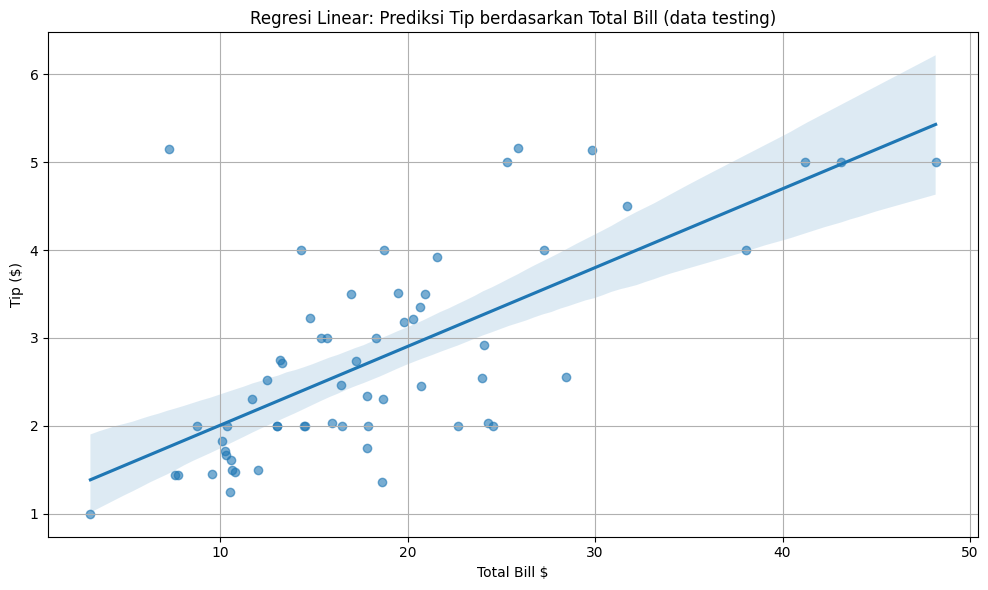

In [8]:
plt.figure(figsize=(10,6))
sns.regplot(x=X_test['total_bill'], y=y_test,
            ci=95, scatter_kws={'alpha': 0.6})
plt.title('Regresi Linear: Prediksi Tip berdasarkan Total Bill (data testing)')
plt.xlabel('Total Bill $')
plt.ylabel('Tip ($)')
plt.grid(True)
plt.tight_layout()
plt.show()

---
## 5. Regularisasi dengan Ridge dan Lasso

Regularisasi menambahkan **penalti** pada besar koefisien agar model tidak overfitting.
- **Ridge (L2):** semua koefisien menyusut mendekati nol.
- **Lasso (L1):** sebagian koefisien bisa menjadi tepat nol (seleksi fitur otomatis).

### 5.1 Memperluas Fitur dan Scaling

Encode kolom kategorikal dengan `pd.get_dummies(..., drop_first=True)`, pisahkan `X_multi` dan `y_multi`, bagi data (75:25, `random_state=42`), lalu scaling dengan `StandardScaler` (`fit_transform` untuk latih, `transform` untuk uji).

In [9]:
tips_encode = pd.get_dummies(tips, columns=['sex','smoker', 'day','time'])
X_multi = tips_encode.drop(columns='tip')
y_multi = tips_encode['tip']
print("Fitur setelah encoding: ", list(X_multi.columns))
print("Ukuran X_multi: ", X_multi.shape)

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.25, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_m)
X_test_scaled = scaler.fit_transform(X_test_m)
print("Rata-rata fitur latih setelah scaling (maks): ", 
       np.abs(X_train_scaled.mean(axis=0)).max().round(6))

Fitur setelah encoding:  ['total_bill', 'size', 'sex_Male', 'sex_Female', 'smoker_Yes', 'smoker_No', 'day_Thur', 'day_Fri', 'day_Sat', 'day_Sun', 'time_Lunch', 'time_Dinner']
Ukuran X_multi:  (244, 12)
Rata-rata fitur latih setelah scaling (maks):  0.0


### 5.2 Melatih OLS, Ridge, dan Lasso

Latih `LinearRegression()`, `Ridge(alpha=1.0)`, dan `Lasso(alpha=0.1)` pada data latih yang sudah di-scaling, lalu bandingkan koefisiennya dalam satu tabel.

In [10]:
ols = LinearRegression().fit(X_train_scaled, y_train_m)
ridge = Ridge(alpha=0.1).fit(X_train_scaled, y_train_m) # penalti kuadrat koefisien
lasso = Lasso(alpha=0.1).fit(X_train_scaled, y_train_m) # penalti absolut koefisien

coef_df = pd.DataFrame({
    'Fitur': X_multi.columns,
    'OLS': ols.coef_,
    'ridge': ridge.coef_,
    'lasso': lasso.coef_,
}).round(2)

print(coef_df)
print("\nJumlah Koefisien Lasso yng Tepat Nol: ", int((lasso.coef_ == 0).sum()))
print("Total |koefisien|  OLS / Ridge / Lasso:",
      np.abs(ols.coef_).sum().round(4),
      np.abs(ridge.coef_).sum().round(4),
      np.abs(lasso.coef_).sum().round(4))

          Fitur   OLS  ridge  lasso
0    total_bill  0.89   0.89   0.78
1          size  0.19   0.19   0.16
2      sex_Male  0.01   0.01   0.00
3    sex_Female -0.01  -0.01  -0.00
4    smoker_Yes -0.07  -0.07  -0.02
5     smoker_No  0.07   0.07   0.00
6      day_Thur -0.04  -0.04   0.00
7       day_Fri  0.04   0.04   0.00
8       day_Sat -0.00  -0.00  -0.00
9       day_Sun  0.01   0.01   0.00
10   time_Lunch  0.04   0.04   0.00
11  time_Dinner -0.04  -0.04  -0.00

Jumlah Koefisien Lasso yng Tepat Nol:  8
Total |koefisien|  OLS / Ridge / Lasso: 1.406 1.4045 0.9586


### 5.3 Visualisasi Perbandingan Koefisien

Ubah tabel koefisien ke bentuk panjang dengan `melt`, lalu buat barplot perbandingan koefisien OLS, Ridge, Lasso (`hue='Model'`).

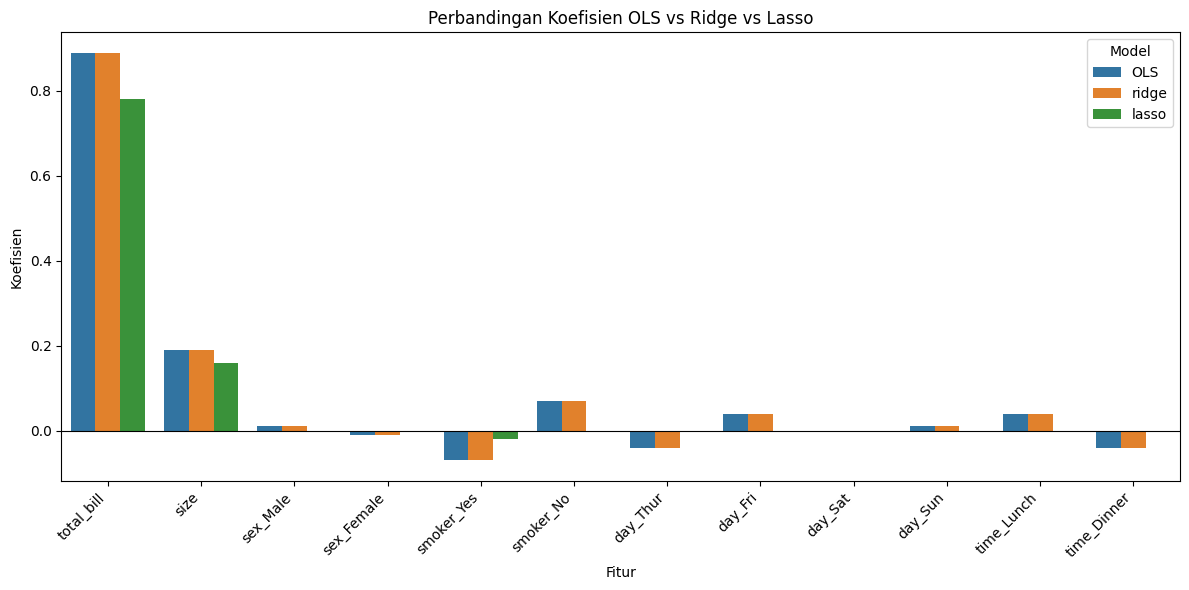

In [ ]:
coef_melted = coef_df.melt(id_vars='Fitur', var_name='Model', value_name='Koefisien')   # bentuk panjang: satu baris per (fitur, model)

plt.figure(figsize=(12, 6))                                  # ukuran gambar
sns.barplot(data=coef_melted, x='Fitur', y='Koefisien', hue='Model')   # satu batang per model di tiap fitur
plt.axhline(0, color='black', linewidth=0.8)                 # garis acuan nol
plt.xticks(rotation=45, ha='right')                          # miringkan nama fitur agar tidak bertumpuk
plt.title('Perbandingan Koefisien OLS vs Ridge vs Lasso')    # judul gambar
plt.tight_layout()                                           # rapikan tata letak
plt.show()


### 5.4 Membandingkan Performa Model

Untuk ketiga model, prediksi data uji lalu cetak RMSE dan R² (gunakan perulangan `for`).

In [ ]:
for nama, mdl in [('OLS', ols), ('Ridge', ridge), ('Lasso', lasso)]:   # ulangi untuk tiap model
    y_hat = mdl.predict(X_test_scaled)                       # prediksi data uji (yang sudah di-scaling)
    rmse_m = np.sqrt(mean_squared_error(y_test_m, y_hat))    # RMSE model ini
    r2_m = r2_score(y_test_m, y_hat)                         # R² model ini
    print(f'{nama:6s} -> RMSE: {rmse_m:.4f} | R2: {r2_m:.4f}')   # satu baris hasil per model
print(f'{"1 fitur":6s} -> RMSE: {rmse:.4f} | R2: {r2:.4f}   (model Bagian 2-4, pembanding)')   # model 1 fitur sebagai pembanding

OLS    -> RMSE: 0.9742 | R2: 0.2866
Ridge  -> RMSE: 0.9740 | R2: 0.2869
Lasso  -> RMSE: 0.9079 | R2: 0.3804
1 fitur -> RMSE: 0.8631 | R2: 0.4401   (model Bagian 2-4, pembanding)


---
## 6. Catatan Penting Praktikum

- Regresi memprediksi angka; OLS meminimalkan jumlah kuadrat error.
- RMSE bersatuan sama dengan target; R² membandingkan dengan tebakan rata-rata.
- Ridge mengecilkan koefisien, Lasso bisa menolkan koefisien.
- Ridge/Lasso wajib scaling; α dipilih dengan cross-validation.
- Satu skor dari satu split tidak cukup untuk menilai model.

---
## 7. Latihan

**Tugas mahasiswa:**

**Studi Kasus: Memprediksi Harga Rumah di California**

Dataset: **California Housing** (`sklearn.datasets.fetch_california_housing`). Dataset ini berisi fitur-fitur seperti pendapatan rata-rata, umur rumah, dan jumlah kamar di sebuah distrik di California; targetnya adalah harga rumah rata-rata di distrik tersebut (satuan: $100.000). *Catatan: pertama kali dipakai, dataset diunduh dari internet, jadi pastikan koneksi aktif.*

**Bagian A — Model Sederhana vs Model Kompleks (OLS)**
1. Jalankan kode awal berikut untuk memuat dataset ke DataFrame:
```python
import pandas as pd
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns=housing.feature_names)
df['PRICE'] = housing.target
```
2. Buatlah scatterplot untuk memvisualisasikan hubungan antara fitur `MedInc` dengan `PRICE`. Berikan judul dan label yang jelas pada plot.
3. **Model sederhana:** definisikan `X` hanya dengan fitur `MedInc` dan `y` sebagai `PRICE`.
4. Bagi data model sederhana menjadi training set (80%) dan testing set (20%). Gunakan `random_state=42`.
5. Latih model `LinearRegression` pada data training yang sederhana.
6. Buat prediksi pada data testing, lalu hitung dan cetak nilai RMSE serta R² untuk model ini. Catat dan jelaskan hasilnya.
7. **Model kompleks:** definisikan ulang `X` untuk menyertakan semua kolom fitur yang tersedia (kecuali `PRICE`).
8. Bagi kembali data (dengan semua fitur) menjadi training set (80%) dan testing set (20%), menggunakan `random_state=42`.
9. Latih model `LinearRegression` yang baru pada data training yang kompleks.
10. Buat prediksi pada data testing, lalu hitung dan cetak nilai RMSE serta R² untuk model kompleks ini.
11. Bandingkan kedua model. Berdasarkan RMSE dan R² yang Anda dapatkan, jawab: **(a)** Model manakah yang memberikan hasil lebih baik? Mengapa demikian? **(b)** Apa yang dapat disimpulkan tentang pentingnya menggunakan lebih banyak fitur dalam kasus ini?

**Bagian B — Regularisasi (Ridge dan Lasso)**
12. Pada fitur-fitur Model Kompleks (semua kolom), lakukan scaling dengan `StandardScaler`, lalu latih `Ridge(alpha=1.0)` dan `Lasso(alpha=0.1)` menggunakan data training yang sudah di-scale.
13. Hitung RMSE dan R² dari Ridge dan Lasso pada data testing (yang juga sudah di-scale), lalu bandingkan dengan hasil OLS Model Kompleks pada nomor 10.
14. Cetak koefisien dari OLS, Ridge, dan Lasso berdampingan dalam satu tabel. Hitung berapa banyak koefisien Lasso yang bernilai tepat 0, dan sebutkan fitur apa saja itu.
15. Berdasarkan hasil nomor 12–14, jawab: **(a)** Apakah Ridge atau Lasso memberikan RMSE/R² yang lebih baik dibanding OLS pada dataset ini? **(b)** Jika tujuannya menyederhanakan model dengan membuang fitur yang kurang penting, model mana yang lebih Anda pilih, Ridge atau Lasso? Jelaskan alasannya berdasarkan konsep regularisasi yang sudah dipelajari.

**Catatan:** Setiap langkah ditulis **Analisis** dan **Konklusi**-nya di cell markdown di bawah kode. Jawaban nomor 11 dan 15 ditulis dalam teks markdown.